In [2]:
import numpy as np
import pandas as pd

sales = pd.read_csv(
    "../data/sales_final.csv",
    parse_dates=["InvoiceDate"],
    dtype={"Invoice": str, "StockCode": str},
)

known = sales.dropna(subset=["Customer ID"])
snapshot = known["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = known.groupby("Customer ID").agg(
    recency=("InvoiceDate", lambda s: (snapshot - s.max()).days),
    frequency=("Invoice", "nunique"),
    monetary=("Revenue", "sum"),
)
print(len(rfm), "customers")
display(rfm.describe().round(1))

logged = np.log1p(rfm[["recency", "frequency", "monetary"]])
X = ((logged - logged.mean()) / logged.std(ddof=0)).to_numpy()

5849 customers


,recency,frequency,monetary
count,5849.0,5849.0,5849.0
mean,200.2,6.2,2849.0
std,208.4,12.7,13980.5
min,1.0,1.0,2.9
25%,26.0,1.0,338.1
50%,95.0,3.0,852.5
75%,379.0,7.0,2231.0
max,739.0,371.0,579704.6


In [3]:
print("RFM monetary total:", round(rfm["monetary"].sum(), 2))
print("Identified revenue in sales_final:", round(known["Revenue"].sum(), 2))
print("Share of revenue with no customer ID:",
      round(100 * (1 - known["Revenue"].sum() / sales["Revenue"].sum()), 1), "%")

RFM monetary total: 16663775.23
Identified revenue in sales_final: 16663775.23
Share of revenue with no customer ID: 13.4 %


In [5]:
inertia, labels, centres = kmeans(X, 4)
rfm["segment"] = labels

profile = rfm.groupby("segment").agg(
    customers=("monetary", "size"),
    median_recency=("recency", "median"),
    median_frequency=("frequency", "median"),
    median_spend=("monetary", "median"),
    total_spend=("monetary", "sum"),
)
profile["pct_customers"] = (100 * profile["customers"] / profile["customers"].sum()).round(1)
profile["pct_revenue"] = (100 * profile["total_spend"] / profile["total_spend"].sum()).round(1)
display(profile.round(0).sort_values("median_spend", ascending=False))

,customers,median_recency,median_frequency,median_spend,total_spend,pct_customers,pct_revenue
segment,,,,,,,
1,1175,16.0,13.0,4893.0,12234254.0,20.0,73.0
3,1454,180.0,5.0,1455.0,2758285.0,25.0,17.0
2,1249,24.0,3.0,716.0,1046641.0,21.0,6.0
0,1971,401.0,1.0,273.0,624595.0,34.0,4.0


In [4]:
def kmeans(X, k, n_init=10, max_iter=100, seed=42):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        centres = [X[rng.integers(len(X))]]          # k-means++ initialisation
        for _ in range(k - 1):
            d2 = ((X[:, None, :] - np.array(centres)[None, :, :]) ** 2).sum(axis=2).min(axis=1)
            centres.append(X[rng.choice(len(X), p=d2 / d2.sum())])
        centres = np.array(centres)
        for _ in range(max_iter):
            d = ((X[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2)
            labels = d.argmin(axis=1)
            new = np.array([X[labels == j].mean(axis=0) if (labels == j).any() else centres[j]
                            for j in range(k)])
            if np.allclose(new, centres):
                break
            centres = new
        d = ((X[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2)
        labels = d.argmin(axis=1)
        inertia = d[np.arange(len(X)), labels].sum()
        if best is None or inertia < best[0]:
            best = (inertia, labels, centres)
    return best


def silhouette(X, labels, chunk=500):
    n, k = len(X), labels.max() + 1
    counts = np.bincount(labels, minlength=k)
    s = np.zeros(n)
    for start in range(0, n, chunk):
        block = X[start:start + chunk]
        D = np.sqrt(((block[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))
        sums = np.stack([D[:, labels == j].sum(axis=1) for j in range(k)], axis=1)
        own = labels[start:start + chunk]
        i = np.arange(len(block))
        a = sums[i, own] / np.maximum(counts[own] - 1, 1)
        means = sums / counts
        means[i, own] = np.inf
        b = means.min(axis=1)
        s[start:start + chunk] = np.where(counts[own] > 1, (b - a) / np.maximum(a, b), 0)
    return s.mean()


results = []
for k in range(2, 9):
    inertia, labels, _ = kmeans(X, k)
    results.append({"k": k, "inertia": round(inertia), "silhouette": round(silhouette(X, labels), 3)})
pd.DataFrame(results)

,k,inertia,silhouette
0,2,8549,0.438
1,3,6317,0.349
2,4,4891,0.366
3,5,4074,0.344
4,6,3535,0.335
5,7,3163,0.307
6,8,2878,0.295


In [6]:
inertia, labels, centres = kmeans(X, 4)
rfm["segment"] = labels

profile = rfm.groupby("segment").agg(
    customers=("monetary", "size"),
    median_recency=("recency", "median"),
    median_frequency=("frequency", "median"),
    median_spend=("monetary", "median"),
    total_spend=("monetary", "sum"),
)
profile["pct_customers"] = (100 * profile["customers"] / profile["customers"].sum()).round(1)
profile["pct_revenue"] = (100 * profile["total_spend"] / profile["total_spend"].sum()).round(1)
display(profile.round(0).sort_values("median_spend", ascending=False))

,customers,median_recency,median_frequency,median_spend,total_spend,pct_customers,pct_revenue
segment,,,,,,,
1,1175,16.0,13.0,4893.0,12234254.0,20.0,73.0
3,1454,180.0,5.0,1455.0,2758285.0,25.0,17.0
2,1249,24.0,3.0,716.0,1046641.0,21.0,6.0
0,1971,401.0,1.0,273.0,624595.0,34.0,4.0


In [7]:
def ari(a, b):
    ct = pd.crosstab(a, b).to_numpy()
    c2 = lambda x: x * (x - 1) / 2
    sum_ij, sum_a, sum_b = c2(ct).sum(), c2(ct.sum(axis=1)).sum(), c2(ct.sum(axis=0)).sum()
    expected = sum_a * sum_b / c2(ct.sum())
    return (sum_ij - expected) / (0.5 * (sum_a + sum_b) - expected)

runs = [kmeans(X, 4, seed=s)[1] for s in range(1, 6)]
print("ARI vs seed-42 solution:", [round(ari(labels, r), 3) for r in runs])

ARI vs seed-42 solution: [np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0)]


In [10]:
print(rfm.nlargest(10, "monetary")["segment_name"].value_counts())

seg1 = rfm[rfm["segment"] == 1]["monetary"].sort_values(ascending=False)
n10 = int(len(seg1) * 0.10)
print("Top 10 customers' share of segment 1 revenue:",
      round(100 * seg1.iloc[:10].sum() / seg1.sum(), 1), "%")
print(f"Top 10% of segment 1 ({n10} customers) share of segment 1 revenue:",
      round(100 * seg1.iloc[:n10].sum() / seg1.sum(), 1), "%")

segment_name
Core high-value    10
Name: count, dtype: int64
Top 10 customers' share of segment 1 revenue: 21.9 %
Top 10% of segment 1 (117 customers) share of segment 1 revenue: 52.1 %


In [11]:
names = {1: "Core high-value", 3: "Lapsing regulars", 2: "Newer customers", 0: "Lost one-time buyers"}
rfm["segment_name"] = rfm["segment"].map(names)

# Is segment 1 driven by a handful of huge accounts?
total = rfm["monetary"].sum()
top10 = rfm["monetary"].nlargest(10).sum()
print("Top 10 customers' share of identified revenue:", round(100 * top10 / total, 1), "%")
seg1 = rfm[rfm["segment"] == 1]["monetary"]
print("Segment 1 median spend excluding its top 10:", round(seg1.nsmallest(len(seg1) - 10).median()))

# Are the 'Recent occasional' customers new?
rfm["first_purchase"] = known.groupby("Customer ID")["InvoiceDate"].min()
display(rfm.groupby("segment_name")["first_purchase"].median())

Top 10 customers' share of identified revenue: 16.1 %
Segment 1 median spend excluding its top 10: 4881


segment_name
Core high-value        2010-01-31 12:49:00
Lapsing regulars       2010-03-30 15:01:30
Lost one-time buyers   2010-09-26 15:50:00
Newer customers        2011-05-06 14:01:00
Name: first_purchase, dtype: datetime64[us]

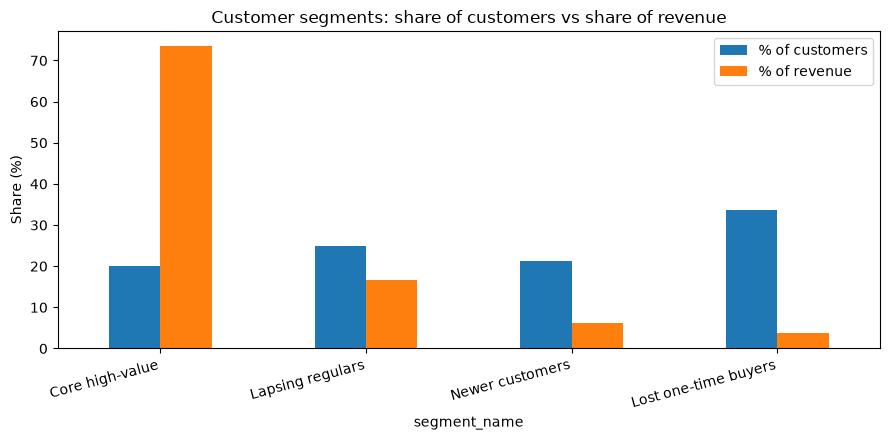

In [12]:
import matplotlib.pyplot as plt
from pathlib import Path

order = ["Core high-value", "Lapsing regulars", "Newer customers", "Lost one-time buyers"]
g = rfm.groupby("segment_name").agg(customers=("monetary", "size"), revenue=("monetary", "sum")).loc[order]
share = pd.DataFrame({
    "% of customers": 100 * g["customers"] / g["customers"].sum(),
    "% of revenue": 100 * g["revenue"] / g["revenue"].sum(),
})
ax = share.plot(kind="bar", figsize=(9, 4.5))
ax.set_ylabel("Share (%)")
ax.set_title("Customer segments: share of customers vs share of revenue")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
Path("../figures").mkdir(exist_ok=True)
plt.savefig("../figures/rfm_segments.png", dpi=150)
plt.show()

profile.to_csv("../figures/rfm_segment_profile.csv")

In [13]:
rfm[["segment_name"]].to_csv("../data/rfm_segments.csv")